<a href="https://colab.research.google.com/github/akatsushikami-arch/HW/blob/main/Kaggle2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# 1. Загрузка данных
df = pd.read_csv('/hotel_bookings.csv')

print(f"Исходный размер таблицы: {df.shape} строк, {df.shape} столбцов")

# 2. Проверка пропусков и повторяющихся записей (дубликатов)
target_cols = ['hotel', 'lead_time', 'stays_in_week_nights', 'stays_in_weekend_nights', 'is_canceled']
print("\nПропуски в выбранных столбцах:")
print(df[target_cols].isna().sum())

duplicates_count = df.duplicated().sum()
print(f"\nПолных дубликатов строк во всей таблице: {duplicates_count}")
print("Решение по дубликатам: не удаляем, так как в таблице нет ID клиента, и одинаковые строки отражают групповые бронирования нескольких номеров.")

# 3. Отбор столбцов и создание вычисляемого столбца Y (общая длительность брони в ночах)
df_clean = df[target_cols].copy()
df_clean['total_nights'] = df_clean['stays_in_week_nights'] + df_clean['stays_in_weekend_nights']

# 4. Фильтрация записей с 0 ночей, сохраняя отменённые брони (is_canceled == 1)
zero_nights = (df_clean['total_nights'] == 0).sum()
df_clean = df_clean[df_clean['total_nights'] > 0].copy()

print(f"\nУдалено записей с длительностью 0 ночей: {zero_nights}")
print(f"Осталось наблюдений для анализа: {len(df_clean)}")
display(df_clean.head())


Исходный размер таблицы: (119390, 32) строк, (119390, 32) столбцов

Пропуски в выбранных столбцах:
hotel                      0
lead_time                  0
stays_in_week_nights       0
stays_in_weekend_nights    0
is_canceled                0
dtype: int64

Полных дубликатов строк во всей таблице: 31994
Решение по дубликатам: не удаляем, так как в таблице нет ID клиента, и одинаковые строки отражают групповые бронирования нескольких номеров.

Удалено записей с длительностью 0 ночей: 715
Осталось наблюдений для анализа: 118675


,hotel,lead_time,stays_in_week_nights,stays_in_weekend_nights,is_canceled,total_nights
2,Resort Hotel,7,1,0,0,1
3,Resort Hotel,13,1,0,0,1
4,Resort Hotel,14,2,0,0,2
5,Resort Hotel,14,2,0,0,2
6,Resort Hotel,0,2,0,0,2


In [6]:
# 1. Функция для сводной статистики по группам
def summarize_by_hotel(data, num_col, group_col='hotel'):
    return data.groupby(group_col)[num_col].agg(
        count='count',
        mean='mean',
        median='median',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    ).round(2)

# 2. Сводка для X (lead_time — число дней от бронирования до заезда)
print("Сводка по X: lead_time (дни до заезда)")
summary_x = summarize_by_hotel(df_clean, 'lead_time')
display(summary_x)

# 3. Сводка для Y (total_nights — длительность брони в ночах)
print("\nСводка по Y: total_nights (длительность брони)")
summary_y = summarize_by_hotel(df_clean, 'total_nights')
display(summary_y)

# 4. Групповой показатель варианта 11: доля отмен (%) по типам гостиниц с сортировкой
cancel_share = (df_clean.groupby('hotel')['is_canceled'].mean() * 100).sort_values(ascending=False).round(2)
print("\nДоля отменённых бронирований по гостиницам (%)")
print(cancel_share)

# 5. Независимая проверка одного результата (медиана lead_time для City Hotel)
direct_check = df_clean[df_clean['hotel'] == 'City Hotel']['lead_time'].median()
table_check = summary_x.loc['City Hotel', 'median']
print(f"\nПроверка медианы lead_time (City Hotel):")
print(f"Прямой расчёт = {direct_check}, значение из таблицы = {table_check}. Совпадают: {direct_check == table_check}")


Сводка по X: lead_time (дни до заезда)


,count,mean,median,q25,q75
hotel,,,,,
City Hotel,78999,110.13,74.0,23.0,164.0
Resort Hotel,39676,93.19,58.0,11.0,155.0



Сводка по Y: total_nights (длительность брони)


,count,mean,median,q25,q75
hotel,,,,,
City Hotel,78999,2.99,3.0,2.0,4.0
Resort Hotel,39676,4.36,4.0,2.0,7.0



Доля отменённых бронирований по гостиницам (%)
hotel
City Hotel      41.87
Resort Hotel    28.00
Name: is_canceled, dtype: float64

Проверка медианы lead_time (City Hotel):
Прямой расчёт = 74.0, значение из таблицы = 74.0. Совпадают: True


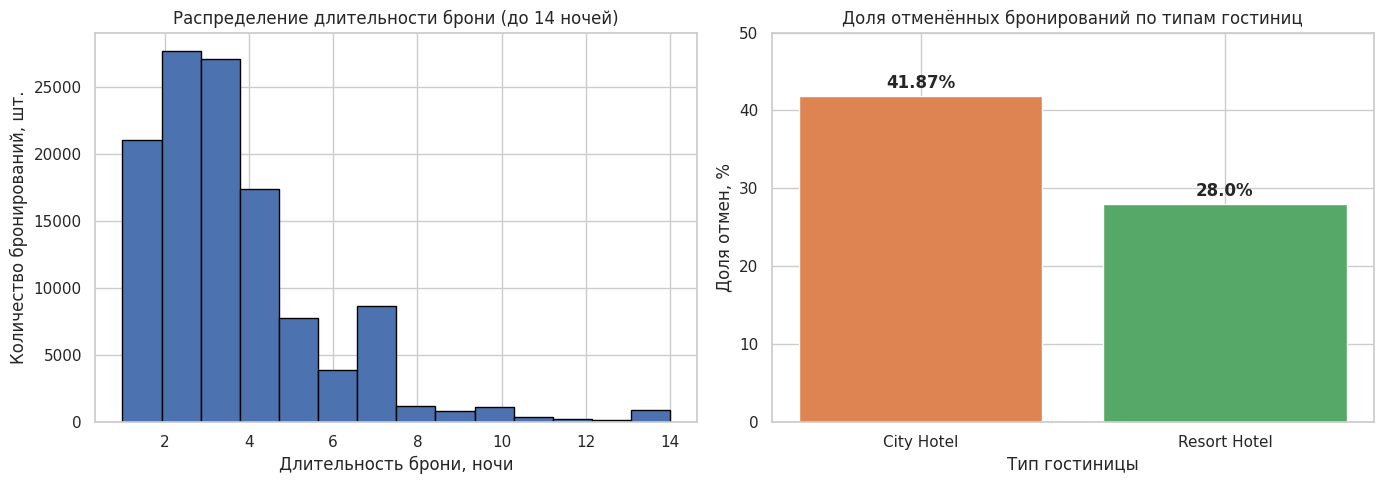

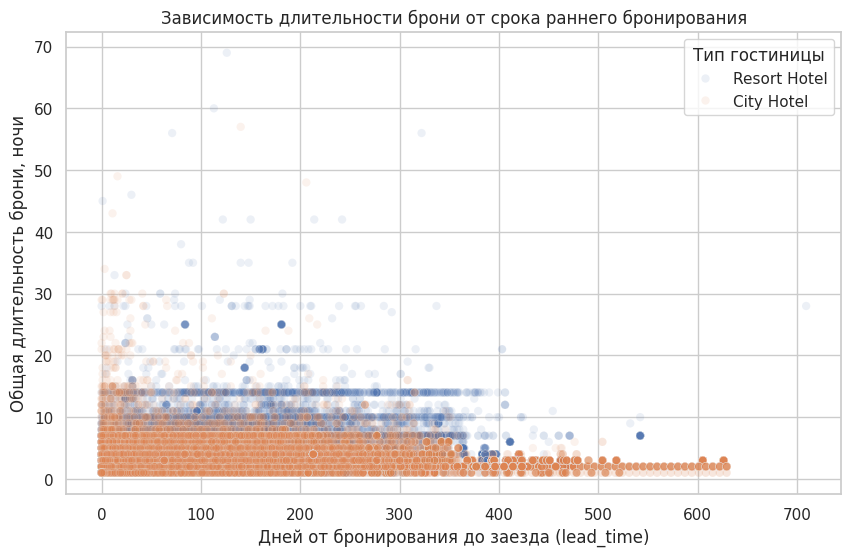

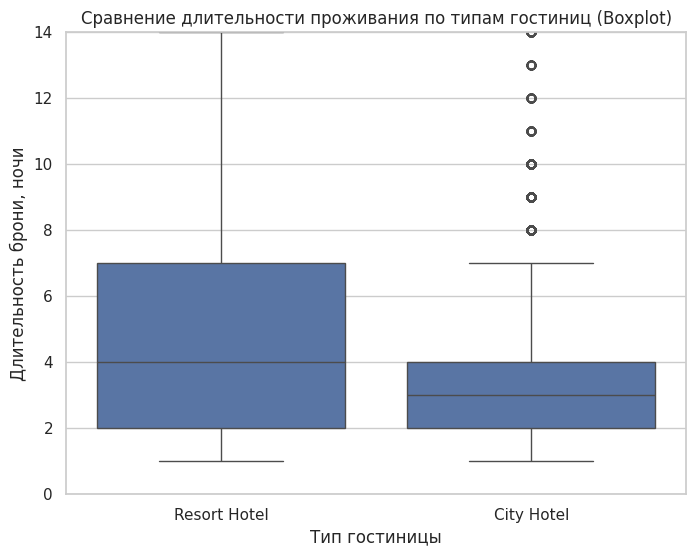

In [8]:
# 1. Matplotlib: фигура из 2 графиков (subplots) с сохранением в файл
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Левый график (axes[0]): гистограмма длительности брони Y
axes[0].hist(
    df_clean[df_clean['total_nights'] <= 14]['total_nights'],
    bins=14,
    color='#4C72B0',
    edgecolor='black'
)
axes[0].set_title('Распределение длительности брони (до 14 ночей)')
axes[0].set_xlabel('Длительность брони, ночи')
axes[0].set_ylabel('Количество бронирований, шт.')

# Правый график (axes[1]): столбчатая диаграмма доли отмен по гостиницам
axes[1].bar(cancel_share.index, cancel_share.values, color=['#DD8452', '#55A868'])
axes[1].set_title('Доля отменённых бронирований по типам гостиниц')
axes[1].set_xlabel('Тип гостиницы')
axes[1].set_ylabel('Доля отмен, %')
axes[1].set_ylim(0, 50)

# Подписи значений над столбцами
for i, v in enumerate(cancel_share.values):
    axes[1].text(i, v + 1, f"{v}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('variant11_matplotlib.png', dpi=300)
plt.show()

# 2. Seaborn: scatterplot с настроенным параметром прозрачности alpha=0.1
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x='lead_time',
    y='total_nights',
    hue='hotel',
    alpha=0.1
)
plt.title('Зависимость длительности брони от срока раннего бронирования')
plt.xlabel('Дней от бронирования до заезда (lead_time)')
plt.ylabel('Общая длительность брони, ночи')
plt.legend(title='Тип гостиницы')
plt.show()

# 3. Seaborn: boxplot для сравнения распределений Y по категориям
plt.figure(figsize=(8, 6))
sns.boxplot(data=df_clean, x='hotel', y='total_nights')
plt.ylim(0, 14)
plt.title('Сравнение длительности проживания по типам гостиниц (Boxplot)')
plt.xlabel('Тип гостиницы')
plt.ylabel('Длительность брони, ночи')
plt.show()


In [9]:
# 1. Межквартильный размах (IQR) для Y (total_nights) и сравнение с pandas
iqr_scipy = stats.iqr(df_clean['total_nights'])
iqr_pandas = df_clean['total_nights'].quantile(0.75) - df_clean['total_nights'].quantile(0.25)
print(f"1. Межквартильный размах (IQR) для total_nights:")
print(f"   scipy.stats.iqr = {iqr_scipy}, pandas (Q75 - Q25) = {iqr_pandas}. Совпадают: {iqr_scipy == iqr_pandas}")

# 2. Ранговая корреляция Спирмена между X (lead_time) и Y (total_nights)
print("\n2. Ранговая корреляция Спирмена (lead_time vs total_nights):")
r_all, p_all = stats.spearmanr(df_clean['lead_time'], df_clean['total_nights'])
print(f"   Вся выборка (n = {len(df_clean)}): r = {r_all:.4f}, p-value = {p_all:.4e}")

for hotel_type, group in df_clean.groupby('hotel'):
    r, p = stats.spearmanr(group['lead_time'], group['total_nights'])
    print(f"   {hotel_type} (n = {len(group)}): r = {r:.4f}, p-value = {p:.4e}")

# 3. Чувствительность оценок центра к крайним значениям (выбросам) для Y
print("\n3. Сравнение оценок центра для total_nights (проверка устойчивости к выбросам):")
for hotel_type, group in df_clean.groupby('hotel'):
    y = group['total_nights']
    mean_val = y.mean()
    trim_val = stats.trim_mean(y, proportiontocut=0.10)  # отбрасываем по 10% самых малых и самых больших значений
    median_val = y.median()
    print(f"   {hotel_type}: Среднее = {mean_val:.2f} | Усечённое среднее (10%) = {trim_val:.2f} | Медиана = {median_val:.2f}")

# 4. Сравнение медианных показателей для отменённых (1) и состоявшихся (0) броней (для выводов по варианту 11)
print("\n4. Медианы lead_time и total_nights в разрезе отмен (0 — не отменено, 1 — отменено):")
cancel_comparison = df_clean.groupby(['hotel', 'is_canceled'])[['lead_time', 'total_nights']].median()
display(cancel_comparison)


1. Межквартильный размах (IQR) для total_nights:
   scipy.stats.iqr = 2.0, pandas (Q75 - Q25) = 2.0. Совпадают: True

2. Ранговая корреляция Спирмена (lead_time vs total_nights):
   Вся выборка (n = 118675): r = 0.3060, p-value = 0.0000e+00
   City Hotel (n = 78999): r = 0.1742, p-value = 0.0000e+00
   Resort Hotel (n = 39676): r = 0.5575, p-value = 0.0000e+00

3. Сравнение оценок центра для total_nights (проверка устойчивости к выбросам):
   City Hotel: Среднее = 2.99 | Усечённое среднее (10%) = 2.77 | Медиана = 3.00
   Resort Hotel: Среднее = 4.36 | Усечённое среднее (10%) = 3.90 | Медиана = 4.00

4. Медианы lead_time и total_nights в разрезе отмен (0 — не отменено, 1 — отменено):


lead_time  total_nights
hotel        is_canceled                         
City Hotel   0                 50.0           3.0
             1                115.0           3.0
Resort Hotel 0                 38.0           3.0
             1                109.0           4.0